In [1]:
# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split ,KFold,cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor,plot_tree
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error,r2_score,mean_squared_error
import joblib

In [2]:
# Read and load dataset 

def read_dataset(filepath):
    try:
        df = pd.read_csv(filepath)
        print("Dataset loaded successfully! \n ")
        return df
    except FileNotFoundError:
        print(f"Error: The file at {filepath} was not found.")
    except pd.errors.EmptyDataError: 
        print("Error: The file is empty.")
    except pd.errors.ParserError:
        print("Error: There was a problem parsing the file.")

In [3]:
# Calling the function 

df= read_dataset(r"D:\Python\pythoncode\Flights.csv")
df

Dataset loaded successfully! 
 


,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...,...,...
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585


In [4]:
# First 5 rows 

def first_5_rows(df):
    head= df.head(5)
    print("First 5 rows: \n")
    return head

In [5]:
# Calling the function 

first_5_rows(df)

First 5 rows: 



,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [6]:
# DataFrame Dimensions

def dataframe_dimension(dataframe):
    shape= dataframe.shape
    return shape

In [7]:
# Calling the function 

dimension= dataframe_dimension(df)
print(f"Dimension: {dimension}")

Dimension: (300153, 12)


In [8]:
# Counts of Values in the DataFtame

def value_count(dataframe,columns):
    counts={}
    for i in columns:
        if i in dataframe.columns:
            counts[i]= dataframe[i].value_counts()
        else:
            counts[i] = f"Column '{i}' does not exist in the DataFrame"
    return counts

In [9]:
# Calling the function 

count = value_count(df,['airline'])
print(f"Value counts of Column: {count}")

Value counts of Column: {'airline': airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64}


In [10]:
# DataFrame summary information

def dataframe_summary(dataframe):
    dataframe.info()

In [11]:
# Calling the function 

print("Dataframe summary information: \n")
dataframe_summary(df)

Dataframe summary information: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [12]:
# Dataframe summary statistics

def summary_statistics(dataframe):
    summary_stats= df.describe()
    print(f"Dataframe summary statistics: \n")
    return summary_stats

In [13]:
# Calling the function 

summary_statistics(df)

Dataframe summary statistics: 



,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [14]:
# Check for datatypes

def data_types(dataframe):
    d_types= df.dtypes
    print("Dataframe data types: \n")
    return d_types

In [15]:
# Calling the function 

data_types(df)

Dataframe data types: 



Unnamed: 0            int64
airline              object
flight               object
source_city          object
departure_time       object
stops                object
arrival_time         object
destination_city     object
class                object
duration            float64
days_left             int64
price                 int64
dtype: object

In [16]:
# Extract Column Names as a List

def dataframe_columns(dataframe):
    return dataframe.columns.tolist()

In [17]:
# Calling the function

print("Existing column names: ")
dataframe_columns(df)

Existing column names: 


['Unnamed: 0',
 'airline',
 'flight',
 'source_city',
 'departure_time',
 'stops',
 'arrival_time',
 'destination_city',
 'class',
 'duration',
 'days_left',
 'price']

In [18]:
# Drop unncessary columns

def unnecessary_columns(dataframe, drop_columns):
    dataframe.drop(columns= drop_columns, axis=1, inplace=True)
    return dataframe

In [19]:
# Calling the function

df= unnecessary_columns(df,['Unnamed: 0', 'flight'])
print("Dropped unncessary columns successfully! \n")
df

Dropped unncessary columns successfully! 



,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...
300148,Vistara,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,Vistara,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,Vistara,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,Vistara,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585


In [20]:
# Check for missing values in the DataFrame

def check_missing_values(dataframe):
    
    # Count NaN/None values
    missing_values = dataframe.isnull().sum()
    
    # Count empty string values
    empty_strings = (dataframe=="").sum()
    
    total_missing = missing_values + empty_strings
    return total_missing

In [21]:
# Calling the function

print("Missing values in the Dataframe: ")
check_missing_values(df)

Missing values in the Dataframe: 


airline             0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

In [22]:
# Check for unique values in the DataFrame

def check_unique_values(dataframe):
    for i in dataframe.columns:
        print(i,":",dataframe[i].unique())

In [23]:
# Calling the function

print("Unique values in the Dataframe: \n")
check_unique_values(df)

Unique values in the Dataframe: 

airline : ['SpiceJet' 'AirAsia' 'Vistara' 'GO_FIRST' 'Indigo' 'Air_India']
source_city : ['Delhi' 'Mumbai' 'Bangalore' 'Kolkata' 'Hyderabad' 'Chennai']
departure_time : ['Evening' 'Early_Morning' 'Morning' 'Afternoon' 'Night' 'Late_Night']
stops : ['zero' 'one' 'two_or_more']
arrival_time : ['Night' 'Morning' 'Early_Morning' 'Afternoon' 'Evening' 'Late_Night']
destination_city : ['Mumbai' 'Bangalore' 'Kolkata' 'Hyderabad' 'Chennai' 'Delhi']
class : ['Economy' 'Business']
duration : [ 2.17  2.33  2.25  2.08 12.25 16.33 11.75 14.5  15.67  3.75  2.5   5.83
  8.    6.   14.67 16.17 18.   23.17 24.17  8.83  4.5  15.25 11.   19.08
 22.83 26.42 17.75 19.58 26.67 15.17 20.83 11.42 22.25 26.   21.75  3.83
  4.42  7.67  8.33 10.42 23.75 19.5   6.5  12.42 21.08 28.17 28.25  9.25
 17.92  7.08 13.83  7.58 15.83 24.42  4.17  4.25  5.08 29.33 17.   27.17
 24.75  5.75 12.75 13.75 17.83  5.5  23.83  5.   26.5  12.83  8.92 11.17
 12.17 15.58 15.75  7.92 13.25 16.   22.7

In [24]:
# Fill categorical missing values with mode 

def fill_categorical_values(dataframe,columns):
    mode= dataframe[columns].mode().iloc[0]
    dataframe[columns]= dataframe[columns].fillna(mode)
    return dataframe[columns]

In [25]:
# Calling the function

print("Filled columns: \n")

fill_categorical_values(df,['departure_time','arrival_time'])

Filled columns: 



,departure_time,arrival_time
0,Evening,Night
1,Early_Morning,Morning
2,Early_Morning,Early_Morning
3,Morning,Afternoon
4,Morning,Morning
...,...,...
300148,Morning,Evening
300149,Afternoon,Night
300150,Early_Morning,Night
300151,Early_Morning,Evening


In [26]:
# Convert a column to datetime format and then timestamps 

def convert_to_datetime(dataframe,columns):
    time_mapping = {
    'Early_Morning': '05:00:00',
    'Morning': '09:00:00',
    'Afternoon': '13:00:00',
    'Evening': '17:00:00',
    'Night': '21:00:00',
    'Late_Night': '23:00:00' }

    for i in columns:
        
        # Map the text values to time strings directly in the DataFrame column
        mapped= dataframe[i].map(time_mapping)

        # Convert the mapped time strings to datetime
        date_time= pd.to_datetime(mapped,format= '%H:%M:%S')
        
        # Convert the datetime to numerical format (in seconds since midnight)
        dataframe[i]= date_time.dt.hour*3600 + date_time.dt.minute*60 + date_time.dt.second

    return dataframe

In [27]:
# Calling the function

df= convert_to_datetime(df, ['departure_time', 'arrival_time'])
print("Time conversion completed :\n")
df

Time conversion completed :



,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,Delhi,61200,zero,75600,Mumbai,Economy,2.17,1,5953
1,SpiceJet,Delhi,18000,zero,32400,Mumbai,Economy,2.33,1,5953
2,AirAsia,Delhi,18000,zero,18000,Mumbai,Economy,2.17,1,5956
3,Vistara,Delhi,32400,zero,46800,Mumbai,Economy,2.25,1,5955
4,Vistara,Delhi,32400,zero,32400,Mumbai,Economy,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...
300148,Vistara,Chennai,32400,one,61200,Hyderabad,Business,10.08,49,69265
300149,Vistara,Chennai,46800,one,75600,Hyderabad,Business,10.42,49,77105
300150,Vistara,Chennai,18000,one,75600,Hyderabad,Business,13.83,49,79099
300151,Vistara,Chennai,18000,one,61200,Hyderabad,Business,10.00,49,81585


In [28]:
# Using label encoder for categorical features 

def label_encoder(dataframe,columns):
    le= LabelEncoder()
    for i in columns:
        dataframe[i]= le.fit_transform(dataframe[i])
    return dataframe

In [29]:
# Calling the function

print("Label Encoding for Categorical Columns:\n")
label_encoder(df,['source_city', 'stops', 'destination_city', 'class'])

Label Encoding for Categorical Columns:



,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,2,61200,2,75600,5,1,2.17,1,5953
1,SpiceJet,2,18000,2,32400,5,1,2.33,1,5953
2,AirAsia,2,18000,2,18000,5,1,2.17,1,5956
3,Vistara,2,32400,2,46800,5,1,2.25,1,5955
4,Vistara,2,32400,2,32400,5,1,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...
300148,Vistara,1,32400,0,61200,3,0,10.08,49,69265
300149,Vistara,1,46800,0,75600,3,0,10.42,49,77105
300150,Vistara,1,18000,0,75600,3,0,13.83,49,79099
300151,Vistara,1,18000,0,61200,3,0,10.00,49,81585


In [30]:
# Using one hot encoding for specific categorical feature

def one_hot_encoding(dataframe,column):
    dataframe= pd.get_dummies(dataframe, columns=[column], drop_first=True)
    return dataframe

In [31]:
# Calling the function

df= one_hot_encoding(df,'airline')
print("One-Hot_Encoding for Airline Column: \n" )
df

One-Hot_Encoding for Airline Column: 



,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara
0,2,61200,2,75600,5,1,2.17,1,5953,False,False,False,True,False
1,2,18000,2,32400,5,1,2.33,1,5953,False,False,False,True,False
2,2,18000,2,18000,5,1,2.17,1,5956,False,False,False,False,False
3,2,32400,2,46800,5,1,2.25,1,5955,False,False,False,False,True
4,2,32400,2,32400,5,1,2.33,1,5955,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
300148,1,32400,0,61200,3,0,10.08,49,69265,False,False,False,False,True
300149,1,46800,0,75600,3,0,10.42,49,77105,False,False,False,False,True
300150,1,18000,0,75600,3,0,13.83,49,79099,False,False,False,False,True
300151,1,18000,0,61200,3,0,10.00,49,81585,False,False,False,False,True


In [32]:
# Calculate the correlation matrix

def correlation_matrix(dataframe):
    correlation= dataframe.corr()
    return correlation

In [33]:
# Calling the function

correlation = correlation_matrix(df)
print("Correlation matrix of Dataframe: \n")
correlation

Correlation matrix of Dataframe: 



,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara
source_city,1.000000,0.027733,0.001819,0.023055,-0.222935,0.000075,0.008619,-0.003568,0.004594,0.044066,0.019370,-0.013484,0.005509,-0.028894
departure_time,0.027733,1.000000,0.016950,-0.090411,-0.008672,-0.031738,0.134241,-0.000502,0.021801,-0.001871,-0.017820,-0.024103,-0.009034,0.018123
stops,0.001819,0.016950,1.000000,-0.033166,-0.012846,0.100262,-0.473860,-0.007047,-0.202620,-0.075445,0.004986,0.155739,0.069300,-0.095073
arrival_time,0.023055,-0.090411,-0.033166,1.000000,-0.020497,0.016177,-0.118747,-0.002843,0.006456,-0.050908,0.016355,0.042957,-0.020621,0.004062
destination_city,-0.222935,-0.008672,-0.012846,-0.020497,1.000000,0.001603,0.001736,-0.005323,0.004795,0.043002,0.018111,-0.004321,0.012991,-0.035747
class,0.000075,-0.031738,0.100262,0.016177,0.001603,1.000000,-0.138710,0.013039,-0.937860,-0.124899,0.194540,0.275477,0.118325,-0.302116
duration,0.008619,0.134241,-0.473860,-0.118747,0.001736,-0.138710,1.000000,-0.039157,0.204222,0.277283,-0.139380,-0.365953,0.008776,0.132430
days_left,-0.003568,-0.000502,-0.007047,-0.002843,-0.005323,0.013039,-0.039157,1.000000,-0.091949,-0.022721,0.030408,0.007839,-0.024414,-0.007002
price,0.004594,0.021801,-0.202620,0.006456,0.004795,-0.937860,0.204222,-0.091949,1.000000,0.070041,-0.194179,-0.280882,-0.114019,0.360816
airline_Air_India,0.044066,-0.001871,-0.075445,-0.050908,0.043002,-0.124899,0.277283,-0.022721,0.070041,1.000000,-0.175687,-0.248781,-0.106858,-0.523242


In [34]:
# Create a heatmap to visualize the correlations

def heatmap(correlation_heatmap):
    plt.figure(figsize=(10, 8))
    sns.heatmap(correlation_heatmap, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap')
    plt.show()
    

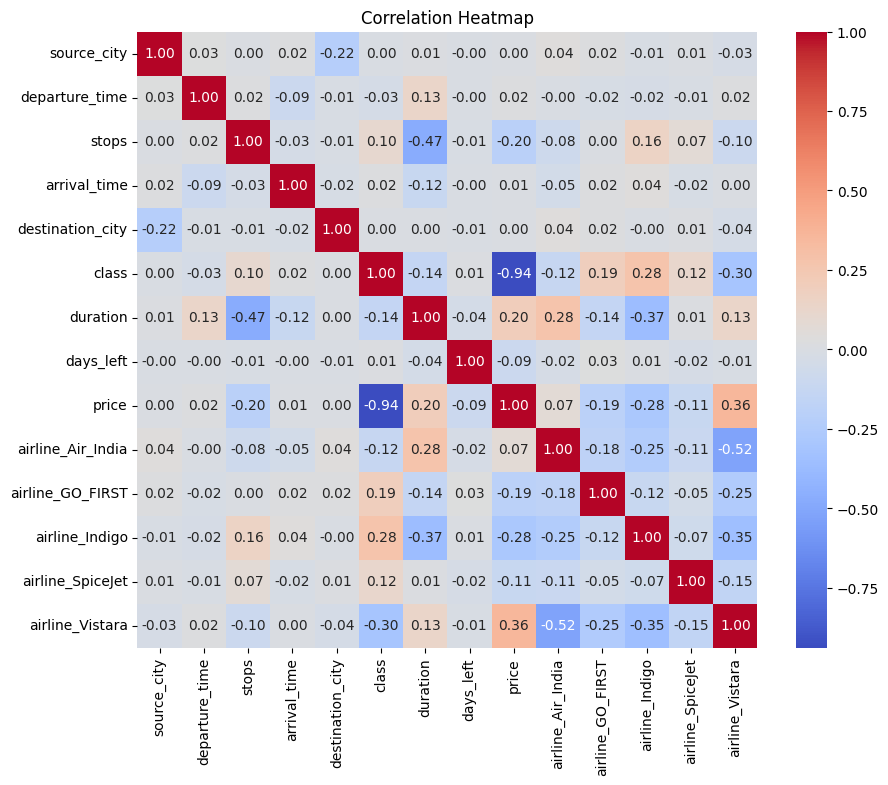

In [35]:
# Calling the function

heatmap(correlation)

In [36]:
# Hisplot Function to visualize the distribution of a Flight Ticket

def hisplot(dataframe,column):
    plt.figure(figsize=(8,6))  
    sns.histplot(x=column, kde=True, bins=30, data=dataframe)
    plt.title('Price Distribution of Flight Tickets')  
    plt.xlabel(column)  
    plt.grid(True) 
    plt.show()

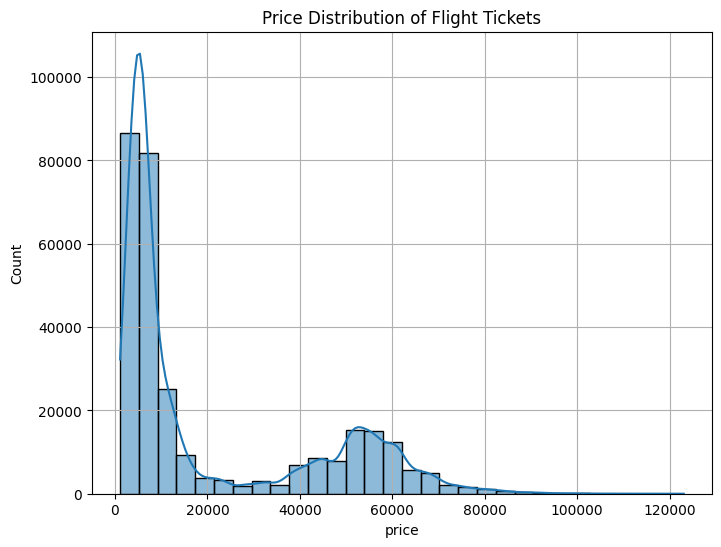

In [37]:
# Calling the function

hisplot(df,'price')

In [38]:
# Line-plot to visualize the impact of Days-Left on Ticket-Price

def line_plot(dataframe,column_1,column_2):
    plt.figure(figsize=(8,6))  
    sns.lineplot(x=column_1, y=column_2, data=df)
    plt.title('Effect of Days Left on Price')  
    plt.xlabel('Days Left Until Flight') 
    plt.ylabel('Ticket Price') 
    plt.show()

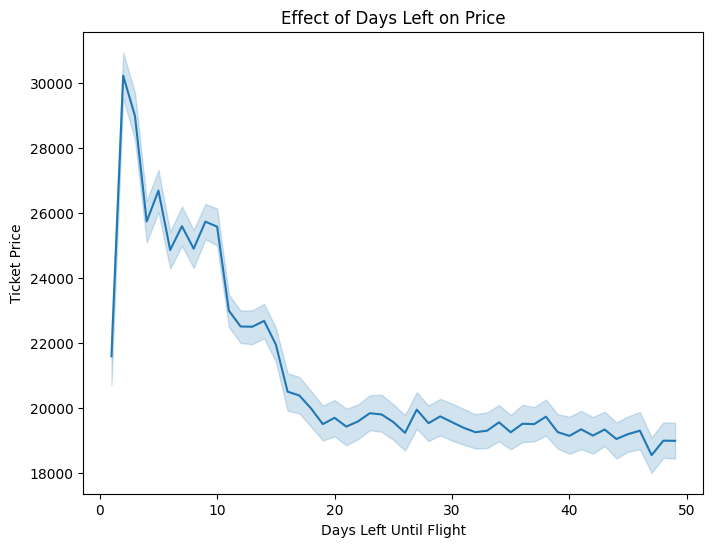

In [39]:
# Calling the function

line_plot(df,'days_left','price')

In [40]:
# Box-plot to visualize the impact of Class on Ticket-Price and check outliers 

def box_plot(dataframe,column_1,column_2):
     plt.figure(figsize=(8,6))  
     sns.boxplot(x=column_1, y=column_2, data=dataframe)
     plt.title('Impact of Class on Ticket Price')  
     plt.xlabel('Class') 
     plt.ylabel('Ticket Price')
     plt.legend(['Buisness : 0','Economy : 1'], title= 'class',loc='upper right',frameon=True,
               edgecolor='black',facecolor='lightgray',title_fontsize='10')
     plt.show()

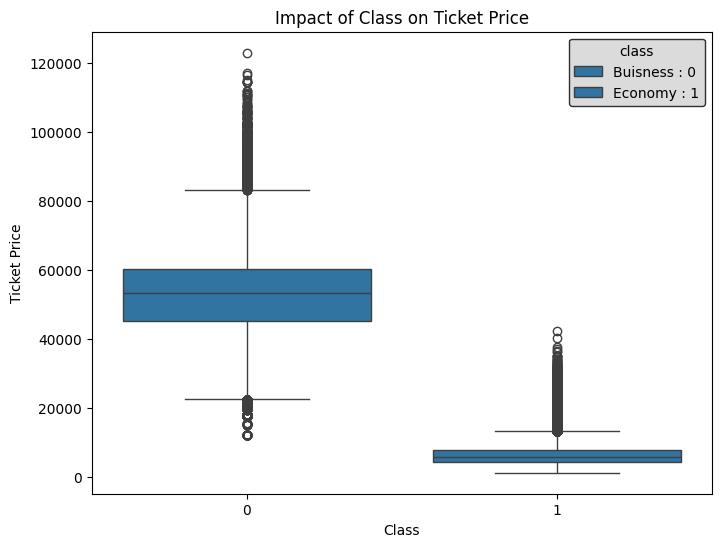

In [41]:
# Calling the function

box_plot(df,'class','price')

In [42]:
# Remove outliers
    
def remove_outliers(dataframe,outlier_column,reference_column,reference_value):
    
    # Filter the data reference_column
    filtered_reference_column= dataframe[dataframe[reference_column] == reference_value]
    print(f"Filtered DataFrame Shape: { filtered_reference_column.shape}\n")

    # Calculate IQR
    Q1= filtered_reference_column[outlier_column].quantile(0.25)
    Q3= filtered_reference_column[outlier_column].quantile(0.75)
    IQR= Q3- Q1
    print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}\n")

    # Determine bounds for outliers
    lower_bound= Q1- 1.5*IQR
    upper_bound= Q3+ 1.5*IQR
    print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}\n")


    # Remove outliers
    outliers_removed= filtered_reference_column[
    (filtered_reference_column[outlier_column] >= lower_bound) & 
    (filtered_reference_column[outlier_column] <= upper_bound)] 
    print(f"Outliers Removed Shape: {outliers_removed.shape}\n")

    # Visualization
    plt.figure(figsize=(12,6))
    
    # Boxplot before outlier removal
    plt.subplot(1,2,1)
    sns.boxplot(data=filtered_reference_column,y=outlier_column)
    plt.title('Before Outlier Removal')

    # Boxplot after outlier removal
    plt.subplot(1,2,2)
    sns.boxplot(data=outliers_removed,y=outlier_column)
    plt.title('After Outlier Removal')

    plt.show()

@ Buisiness Class:

Filtered DataFrame Shape: (93487, 14)

Q1: 45185.0, Q3: 60396.0, IQR: 15211.0

Lower Bound: 22368.5, Upper Bound: 83212.5

Outliers Removed Shape: (89837, 14)



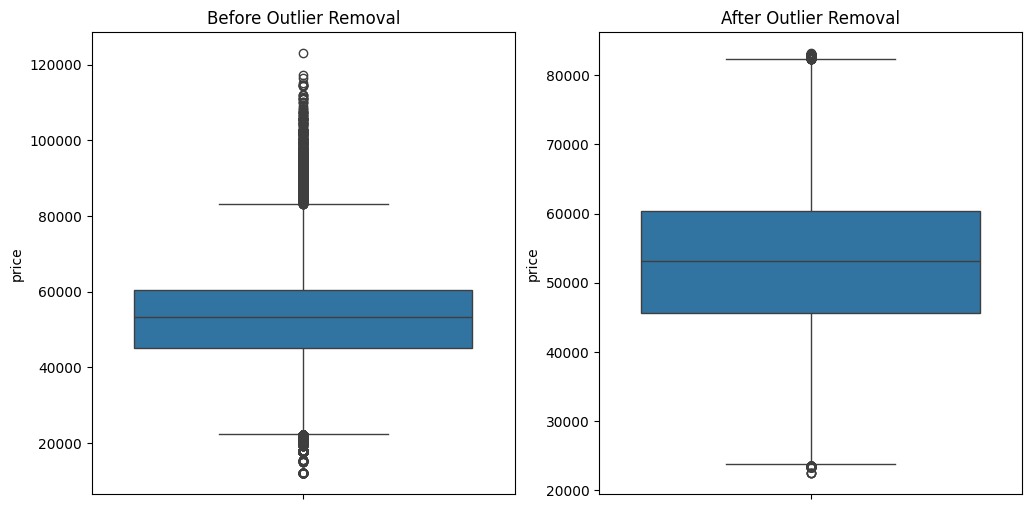

In [43]:
# Calling the function

print("@ Buisiness Class:\n")
remove_outliers(df,'price','class',0)

@ Economy Class:

Filtered DataFrame Shape: (206666, 14)

Q1: 4173.0, Q3: 7746.0, IQR: 3573.0

Lower Bound: -1186.5, Upper Bound: 13105.5

Outliers Removed Shape: (192917, 14)



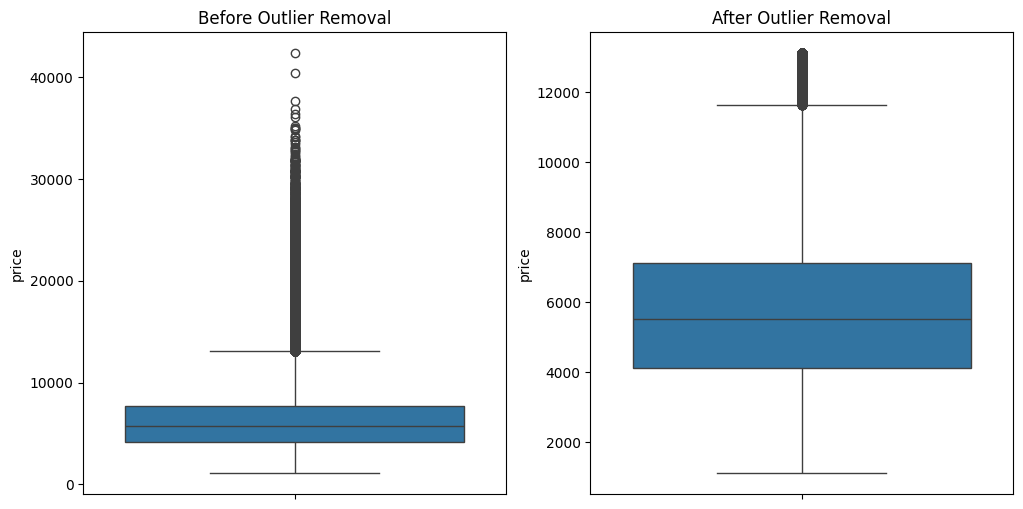

In [44]:
# Calling the function

print("@ Economy Class:\n")
remove_outliers(df,'price','class',1)

In [45]:
# Pairplot to visualize price distribution across different airlines

def pairplot(dataframe,columns):
        sns.pairplot(data=dataframe,vars= columns)
        plt.suptitle('Price Distribution Across Different Airlines', y=1.02)
        plt.show()

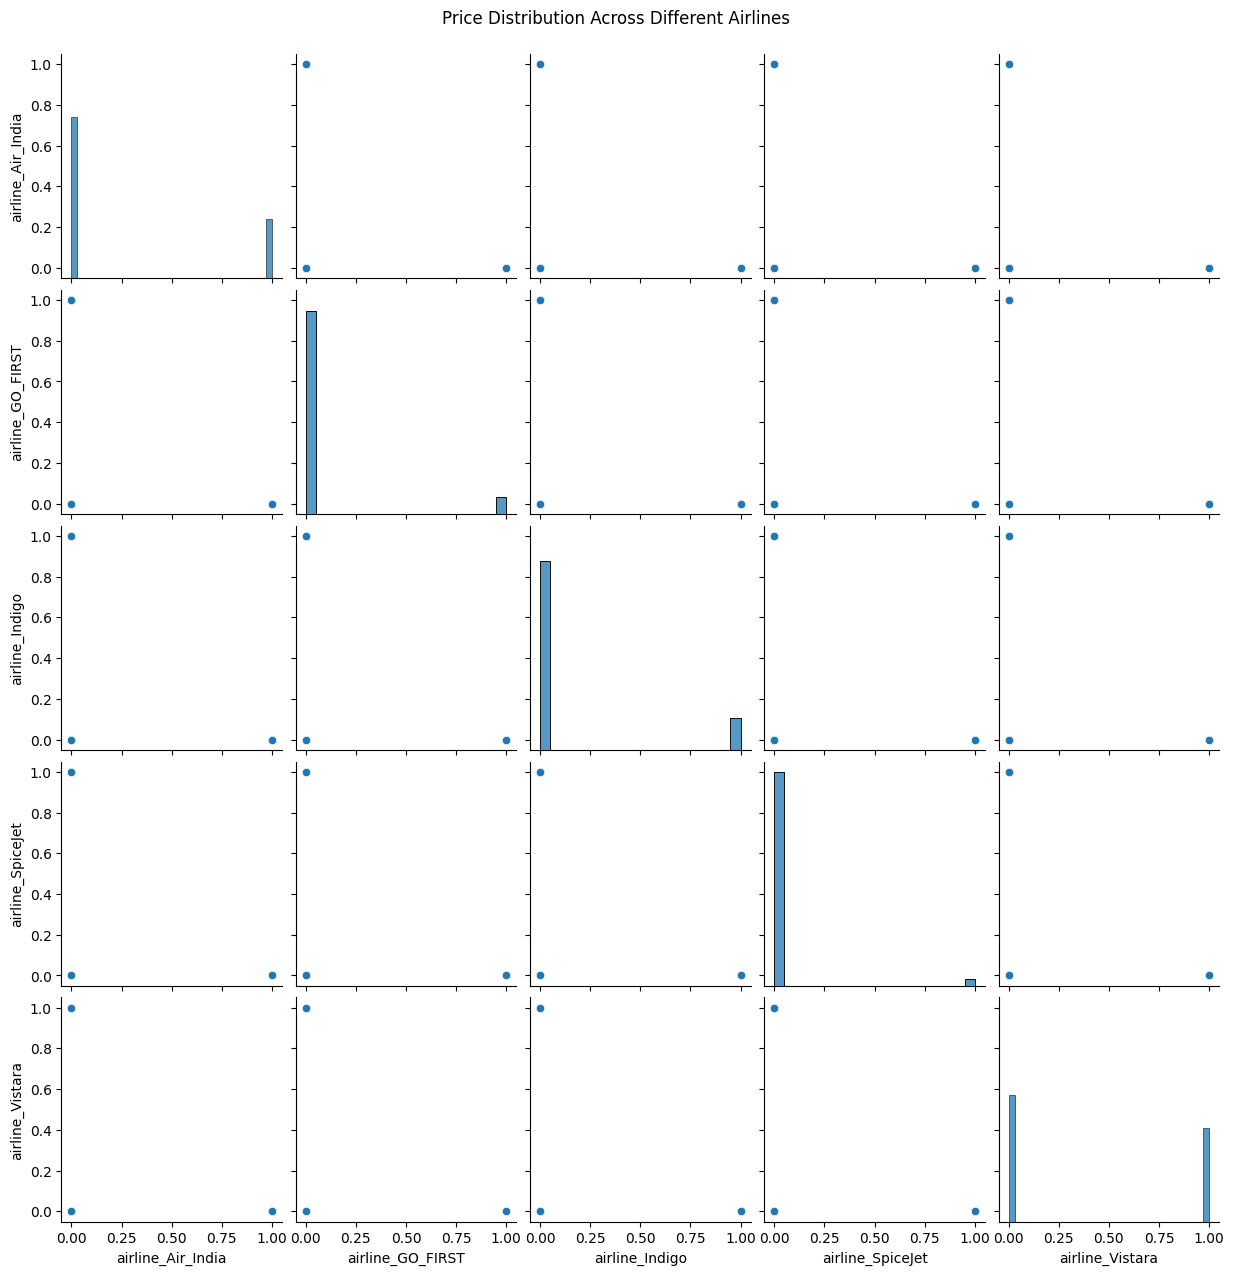

In [46]:
# Calling the function

pairplot(df,['airline_Air_India','airline_GO_FIRST','airline_Indigo','airline_SpiceJet','airline_Vistara'])

In [47]:
# Define features and targets 

def features_target(dataframe,features,target):
    X= dataframe[features]
    y=dataframe[target]
    
    print("Features (X):")
    print(X.head())  # Print the first few rows of features
    
    print("\nTarget (y):")
    print(y.head())  # Print the first few rows of the target
    
    return X,y

In [48]:
# Calling the function

X,y= features_target(df,['source_city','departure_time','stops','arrival_time','destination_city','class',
                    'duration','days_left','airline_Air_India','airline_GO_FIRST','airline_Indigo',
                    'airline_SpiceJet','airline_Vistara'],'price')

Features (X):
   source_city  departure_time  stops  arrival_time  destination_city  class  \
0            2           61200      2         75600                 5      1   
1            2           18000      2         32400                 5      1   
2            2           18000      2         18000                 5      1   
3            2           32400      2         46800                 5      1   
4            2           32400      2         32400                 5      1   

   duration  days_left  airline_Air_India  airline_GO_FIRST  airline_Indigo  \
0      2.17          1              False             False           False   
1      2.33          1              False             False           False   
2      2.17          1              False             False           False   
3      2.25          1              False             False           False   
4      2.33          1              False             False           False   

   airline_SpiceJet  airline_V

In [49]:
# Splitting the data

def splitting_data(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    return X_train, X_test, y_train, y_test

In [50]:
# Calling the function

X_train, X_test, y_train, y_test = splitting_data(X, y) 

In [51]:
# StandardScaler

def standard_scaler(X_train,X_test):
    scaler= StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    return X_train_scaled,X_test_scaled

In [52]:
# Calling the function

X_train_scaled,X_test_scaled = standard_scaler(X_train,X_test)

In [53]:
# Function for Linear Regression with Cross-Validation

def linear_regression(X_train,X_test,y_train,y_test):
    
    LR_model = LinearRegression()
    
    kfold = KFold(n_splits=5, shuffle=True, random_state=42)

    # Cross-validation scores (negative MSE)
    LR_cross_val= cross_val_score( LR_model,X_train,y_train, cv=kfold, scoring='neg_mean_squared_error')
    print(f"* Linear Regression Cross-Validation Scores:\n {LR_cross_val}\n")

    # Fit the model
    LR_model.fit(X_train,y_train)

    # Prediction
    LR_y_predict = LR_model.predict(X_test)
    print(f"* Linear Regression Predictions:\n{ LR_y_predict}\n")
    
    # Model Evaluation Metrics
    
    print("\nLinear Regression Model Evaluation Metrics:\n")
    LR_mae= mean_absolute_error (y_test,LR_y_predict)
    print(f"1- Mean Absolute Error: {LR_mae:.2f}\n")
    
    LR_r2= r2_score(y_test,LR_y_predict)
    print(f"2- R2 Score: {LR_r2:.2f}\n")
    
    LR_mse= mean_squared_error(y_test,LR_y_predict)
    print(f"3- Mean Squared Error: {LR_mse:.2f}\n")
    
    LR_rmse= np.sqrt(LR_mse)
    print(f"4- Root Mean Squared Error: {LR_rmse:.2f}\n")

    # Visualization

    plt.figure(figsize=(8,4))
    plt.scatter(y_test,LR_y_predict,color='blue', alpha=0.6)
    plt.plot([y_test.min(),y_test.max()],[y_test.min(), y_test.max()],color='orange',linestyle='--', lw=3)
    plt.title('Linear Regression: Actual vs Predicted Values')
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.grid(True)
    plt.show()

    return  LR_y_predict , LR_cross_val

* Linear Regression Cross-Validation Scores:
 [-48363925.8138603  -48412114.12701605 -49212571.8410189
 -49387030.80440757 -48791832.09735704]

* Linear Regression Predictions:
[ 3921.50821039 53099.49908806  7982.99463219 ...  5865.74453985
 -1356.6306095  58940.11500525]


Linear Regression Model Evaluation Metrics:

1- Mean Absolute Error: 4623.46

2- R2 Score: 0.91

3- Mean Squared Error: 48942966.32

4- Root Mean Squared Error: 6995.92



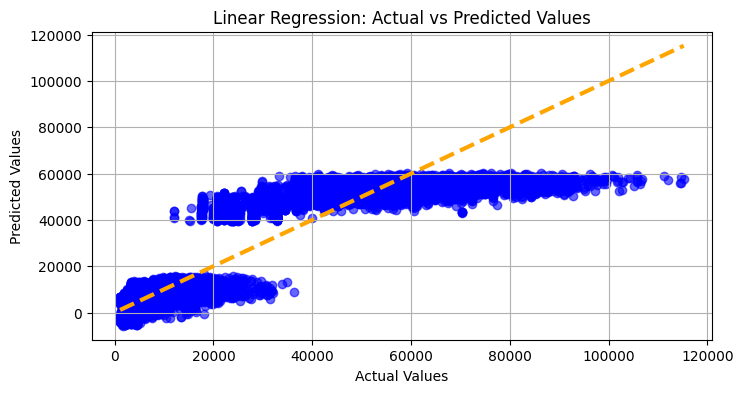

In [54]:
# Calling the function 

LR_y_predict , LR_cross_val= linear_regression(X_train_scaled,X_test_scaled,y_train,y_test)


In [55]:
# Function for Random Forest Regressor with Cross-Validation

def random_forest_regressor(X_train,X_test,y_train,y_test):
    
    RFR_model = RandomForestRegressor(n_estimators=100 ,random_state=42)
    
    kfold = KFold(n_splits=5, shuffle=True, random_state=42)

    # Cross-validation scores (negative MSE)
    RFR_cross_val= cross_val_score(RFR_model,X_train,y_train, cv=kfold, scoring='neg_mean_squared_error')
    print(f"* Random Forest Regressor Cross-Validation Scores:\n {RFR_cross_val}\n")

    # Fit the model
    RFR_model.fit(X_train,y_train)

    # Prediction
    RFR_y_predict = RFR_model.predict(X_test)
    print(f"* Random Forest Regressor Predictions:\n{ RFR_y_predict}\n")
    
    # Model Evaluation Metrics
    
    print("\nRandom Forest Regressor Evaluation Metrics:\n")
    RFR_mae= mean_absolute_error (y_test,RFR_y_predict)
    print(f"1- Mean Absolute Error: {RFR_mae:.2f}\n")
    
    RFR_r2= r2_score(y_test,RFR_y_predict)
    print(f"2- R2 Score: {RFR_r2:.2f}\n")
    
    RFR_mse= mean_squared_error(y_test,RFR_y_predict)
    print(f"3- Mean Squared Error: {RFR_mse:.2f}\n")
    
    RFR_rmse= np.sqrt(RFR_mse)
    print(f"4- Root Mean Squared Error: {RFR_rmse:.2f}\n")

    # Visualization

    plt.figure(figsize=(8,4))
    plt.scatter(y_test,RFR_y_predict,color='blue', alpha=0.6)
    plt.plot([y_test.min(),y_test.max()],[y_test.min(), y_test.max()],color='orange',linestyle='--', lw=3)
    plt.title('Random Forest Regressor: Actual vs Predicted Values')
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.grid(True)
    plt.show()

    return  RFR_y_predict , RFR_cross_val

* Random Forest Regressor Cross-Validation Scores:
 [-7635953.4288901  -7571496.77766463 -7833420.75417059 -7813977.7520519
 -7725640.68110791]

* Random Forest Regressor Predictions:
[ 7274.55 70669.84  6195.   ...  6717.22  4424.78 70773.13]


Random Forest Regressor Evaluation Metrics:

1- Mean Absolute Error: 1082.27

2- R2 Score: 0.99

3- Mean Squared Error: 7618630.83

4- Root Mean Squared Error: 2760.19



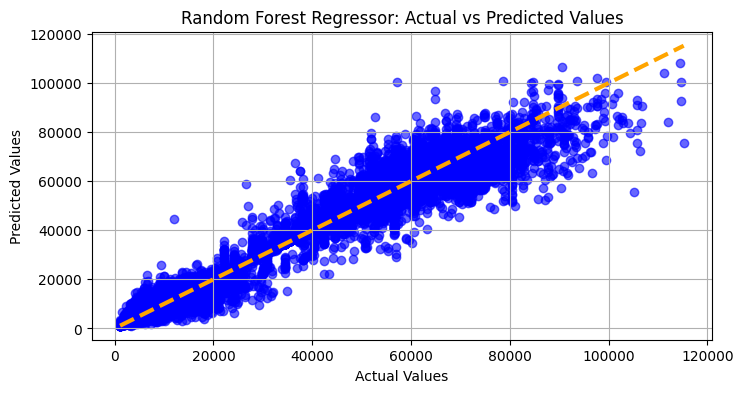

In [56]:
# Calling the function 

RFR_y_predict,RFR_cross_val= random_forest_regressor(X_train_scaled,X_test_scaled,y_train,y_test)


In [57]:
# Function for Decision Tree Regressor with Cross-Validation

def decision_tree_regressor(X_train,X_test,y_train,y_test):
    
    DTR_model = DecisionTreeRegressor()
    
    kfold = KFold(n_splits=5, shuffle=True, random_state=42)

    # Cross-validation scores (negative MSE)
    DTR_cross_val= cross_val_score(DTR_model,X_train,y_train, cv=kfold, scoring='neg_mean_squared_error')
    print(f"* Decision Tree Regressor Cross-Validation Scores:\n {DTR_cross_val}\n")

    # Fit the model
    DTR_model.fit(X_train,y_train)

    # Prediction
    DTR_y_predict = DTR_model.predict(X_test)
    print(f"* Decision Tree Regressor Predictions:\n{ DTR_y_predict}\n")
    
    # Model Evaluation Metrics
    
    print("\nDecision Tree Regressor Evaluation Metrics:\n")
    DTR_mae= mean_absolute_error (y_test,DTR_y_predict)
    print(f"1- Mean Absolute Error: {DTR_mae:.2f}\n")
    
    DTR_r2= r2_score(y_test,DTR_y_predict)
    print(f"2- R2 Score: {DTR_r2:.2f}\n")
    
    DTR_mse= mean_squared_error(y_test,DTR_y_predict)
    print(f"3- Mean Squared Error: {DTR_mse:.2f}\n")
    
    DTR_rmse= np.sqrt(DTR_mse)
    print(f"4- Root Mean Squared Error: {DTR_rmse:.2f}\n")

    # Visualization

    plt.figure(figsize=(8,4))
    plt.scatter(y_test,DTR_y_predict,color='blue', alpha=0.6)
    plt.plot([y_test.min(),y_test.max()],[y_test.min(), y_test.max()],color='orange',linestyle='--', lw=3)
    plt.title('Decision Tree Regressor: Actual vs Predicted Values')
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.grid(True)
    plt.show()

    return  DTR_y_predict ,DTR_cross_val

* Decision Tree Regressor Cross-Validation Scores:
 [-12010193.63388802 -12038779.23666204 -12503508.23877124
 -12671960.97852    -12187666.05271901]

* Decision Tree Regressor Predictions:
[ 7366. 72783.  6195. ...  6314.  5082. 70049.]


Decision Tree Regressor Evaluation Metrics:

1- Mean Absolute Error: 1146.11

2- R2 Score: 0.98

3- Mean Squared Error: 11922457.17

4- Root Mean Squared Error: 3452.89



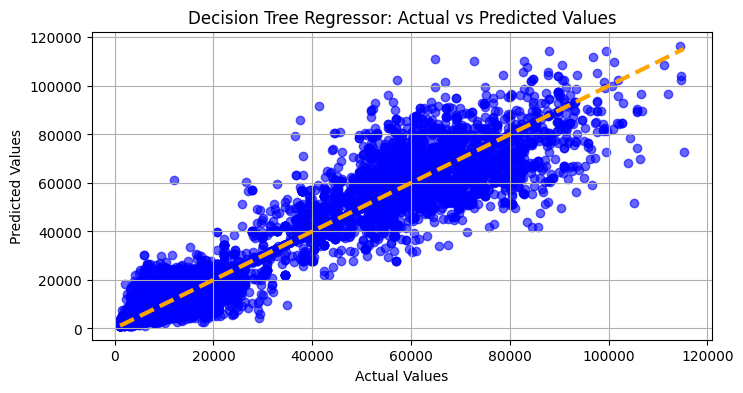

In [58]:
# Calling the function 

DTR_y_predict ,DTR_cross_val= decision_tree_regressor(X_train_scaled,X_test_scaled,y_train,y_test)


In [59]:
# Save the Models using joblib
